HOUSE PRICE DATASET
    House_Size  House_Price
0          500           15
1          600           19
2          700           24
3          800           30
4          900           37
5         1000           45
6         1100           54
7         1200           64
8         1300           75
9         1400           87
10        1500          100
11        1600          114
12        1700          129
13        1800          145
14        1900          162

Model trained successfully!

Actual House Prices:
[ 87 114  15]

Predicted House Prices:
[ 87. 114.  15.]

Mean Squared Error: 7.924160383672078e-25
R2 Score: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


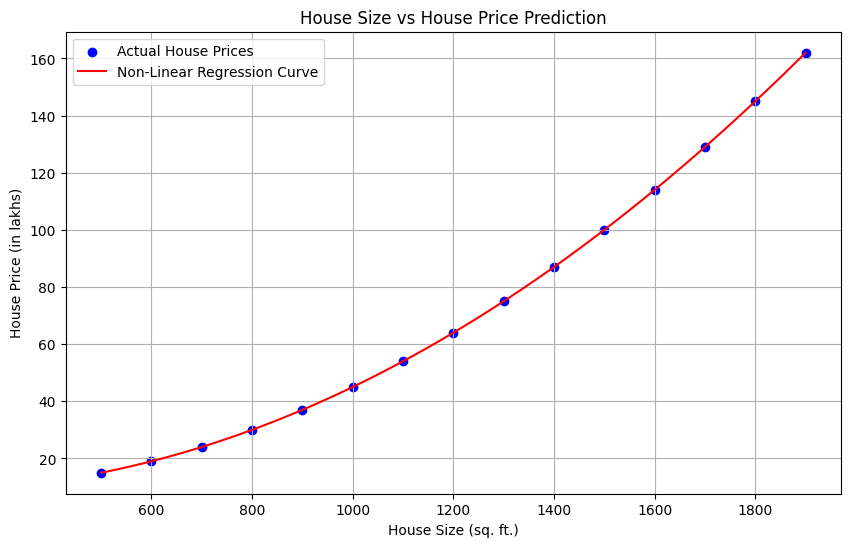

In [ ]:
#AP24110011267
# NON-LINEAR REGRESSION
# House Size vs House Price Prediction

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create dataset
data = {
    'House_Size': [
        500, 600, 700, 800, 900,
        1000, 1100, 1200, 1300, 1400,
        1500, 1600, 1700, 1800, 1900
    ],
    'House_Price': [
        15, 19, 24, 30, 37,
        45, 54, 64, 75, 87,
        100, 114, 129, 145, 162
    ]
}

df = pd.DataFrame(data)

print("HOUSE PRICE DATASET")
print(df)

# Step 3: Separate input and output variables
X = df[['House_Size']]
y = df['House_Price']

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Convert input into polynomial features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Step 6: Create and train the model
model = LinearRegression()
model.fit(X_train_poly, y_train)

print("\nModel trained successfully!")

# Step 7: Predict house prices
y_pred = model.predict(X_test_poly)

print("\nActual House Prices:")
print(y_test.values)

print("\nPredicted House Prices:")
print(y_pred)

# Step 8: Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Squared Error:", mse)
print("R2 Score:", r2)

# Step 9: Plot the regression curve
X_curve = np.linspace(
    X['House_Size'].min(),
    X['House_Size'].max(),
    100
).reshape(-1, 1)

X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)

plt.figure(figsize=(10, 6))

plt.scatter(
    X['House_Size'], y,
    color='blue', label='Actual House Prices'
)

plt.plot(
    X_curve, y_curve,
    color='red', label='Non-Linear Regression Curve'
)

plt.xlabel("House Size (sq. ft.)")
plt.ylabel("House Price (in lakhs)")
plt.title("House Size vs House Price Prediction")
plt.legend()
plt.grid(True)
plt.show()

# Step 10: Predict price for a new house
size = float(input("Enter house size in sq. ft.: "))

new_house = pd.DataFrame({'House_Size': [size]})
new_house_poly = poly.transform(new_house)

predicted_price = model.predict(new_house_poly)

print("House Size:", size, "sq. ft.")
print("Predicted House Price:",
      round(predicted_price[0], 2), "lakhs")
#AP24110011267